### Implementing Adaline Algorithm

In [ ]:
import numpy as np

class AdalineGD:
    """ADAptive LInear NEuron classifier.
        Parameters
        ------------
        eta : float
            Learning rate (between 0.0 and 1.0)
        n_iter : int
            Passes over the training dataset.
        random_state : int
            Random number generator seed for random weight initialization.
        Attributes
        -----------
        w_ : 1d-array
            Weights after fitting.
        b_ : Scalar
            Bias unit after fitting.
        losses_ : list
            Mean squared error loss function values in each epoch.
    """
    
    def __init__(self, eta: np.float16 = 0.01, n_iter: np.int16 = 50, random_state: np.int16 = 1):
        self.eta = eta
        self.n_iter = n_iter
        self.random_state = random_state

    def fit(self, X: np.ndarray, y: np.ndarray):
        
        """Fit training data.
            Parameters
            ----------
            X : {array-like}, shape = [n_examples, n_features]
            Training vectors, where n_examples is the number of
            examples and n_features is the number of features.
            y : array-like, shape = [n_examples]
            Target values.
            Returns
            -------
            self : object
        """
        rgen = np.random.RandomState(self.random_state)
        self.w_ = rgen.normal(loc=0.0, scale=0.01,
        size = X.shape[1])
        self.b_ = np.float64(0.)
        self.losses_ = []
        
        for _ in range(self.n_iter):
            net_input = self.net_input(X)
            output = self.activation(net_input)
            errors = (y - output)
            self.w_ += self.eta * 2.0 * X.T.dot(errors) / X.shape[0] # (2 * l_rate * (y - output) * X
            self.b_ += self.eta * 2.0 * errors.mean()
            loss = (errors**2).mean()
            self.losses_.append(loss)
        return self
    def net_input(self, X):
        """Calculate the net input:(z)"""
        return np.dot(X, self.w_) + self.b_
    
    def activation(self, X):
        """Return the linear activation( Identity function)"""
        return X
    
    def predict(self, X):
        """Return class label"""
        return np.where(self.activation(self.net_input(X))>= 0.5, 1, 0)

#### Load the data

In [3]:
import pandas as pd
s = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'
print('From URL:', s)
df = pd.read_csv(s,
    header=None,
    encoding='utf-8')
df.tail()

From URL: https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data


,0,1,2,3,4
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica
149,5.9,3.0,5.1,1.8,Iris-virginica


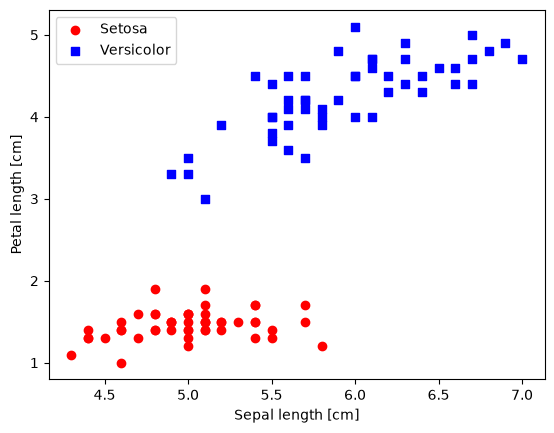

In [4]:
import matplotlib.pyplot as plt
# select setosa and versicolor
y = df.iloc[0:100, 4].values
y = np.where(y == 'Iris-setosa', 0, 1)
# extract sepal length and petal length
X = df.iloc[0:100, [0, 2]].values
# plot data
plt.scatter(X[:50, 0], X[:50, 1], color='red', marker='o', label='Setosa')
plt.scatter(X[50:100, 0], X[50:100, 1], color='blue', marker='s', label='Versicolor')
plt.xlabel('Sepal length [cm]')
plt.ylabel('Petal length [cm]')
plt.legend(loc='upper left')
plt.show()

### Let's plot the number of epoches for two different learning rates 𝜂 (0.1 & 0.0001)

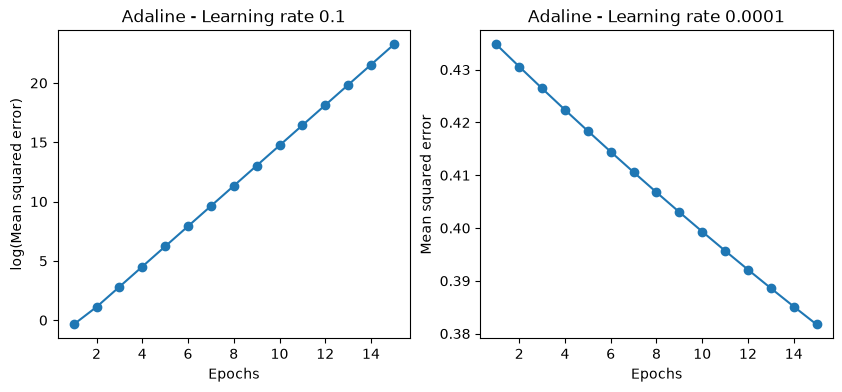

In [12]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
ada1 = AdalineGD(n_iter=15, eta=0.1).fit(X, y)
ax[0].plot(range(1, len(ada1.losses_) + 1), np.log10(ada1.losses_), marker='o')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('log(Mean squared error)')
ax[0].set_title('Adaline - Learning rate 0.1')
ada2 = AdalineGD(n_iter=15, eta=0.0001).fit(X, y)
ax[1].plot(range(1, len(ada2.losses_) + 1), ada2.losses_, marker='o')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Mean squared error')
ax[1].set_title('Adaline - Learning rate 0.0001')
plt.show()